# CO2 backfill: training and testing the models

This notebook trains the models from our methodology on the cleaned dataset (`co2_backfill_train.csv`) and tests them honestly.

**What we predict:** porosity (%) of the backfill. Lower porosity means denser, stronger backfill, so the **best CO2 injection time is where porosity is lowest**.

**Inputs:** CO2 injection time, cement fraction, stirring speed, CO2 flow rate, curing age.

**Three tests**
1. Random split: the common way, but misleading here (shown on purpose).
2. Leave-one-time-out: hide every row at one injection time, predict it, repeat for all times.
3. Peak test: hide the 10 min rows (then 8 and 10 min) and check where each model puts the lowest porosity.

Run the cells from top to bottom (Runtime > Run all). The whole notebook takes about 5 to 10 minutes.

## 1. Setup and load the data

In [1]:
import os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
np.random.seed(42)

CSV = "co2_backfill_train.csv"
if not os.path.exists(CSV):              # in Colab: choose the file when asked
    from google.colab import files
    files.upload()

df = pd.read_csv(CSV)
INPUTS = ["co2_time_min", "cement_fraction", "stirring_rpm", "co2_flow_L_min", "curing_days"]
TARGET = "porosity_pct"
print(df.shape, "rows x columns |", df.recipe.nunique(), "recipes")
print("Injection times:", sorted(df.co2_time_min.unique()))
df.head()

(786, 8) rows x columns | 81 recipes
Injection times: [np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(5.0), np.float64(8.0), np.float64(10.0), np.float64(15.0), np.float64(20.0)]


,recipe,cement_ratio,cement_fraction,stirring_rpm,co2_flow_L_min,curing_days,co2_time_min,porosity_pct
0,1:4_500rpm_1Lmin_3d,1:4,0.2,500,1,3,0.0,13.22188
1,1:4_500rpm_1Lmin_3d,1:4,0.2,500,1,3,0.5,13.23184
2,1:4_500rpm_1Lmin_3d,1:4,0.2,500,1,3,1.0,11.64004
3,1:4_500rpm_1Lmin_3d,1:4,0.2,500,1,3,1.5,11.54055
4,1:4_500rpm_1Lmin_3d,1:4,0.2,500,1,3,2.0,11.24209


## 2. Look at the data first
One recipe (ratio 1:6, 800 rpm, 1 L/min) at the three curing ages. Porosity is lowest at 10 min, and falls with longer curing.

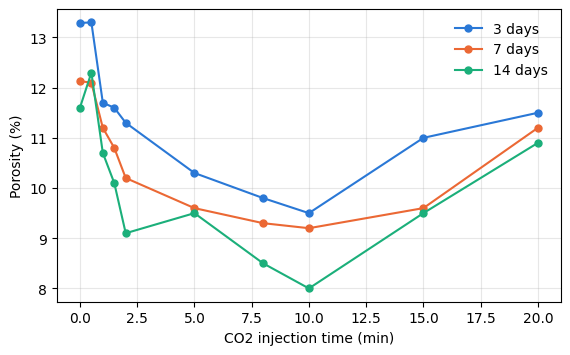

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for days, col in [(3, "#2a78d6"), (7, "#eb6834"), (14, "#1baf7a")]:
    g = df[(df.cement_ratio == "1:6") & (df.stirring_rpm == 800) & (df.co2_flow_L_min == 1) & (df.curing_days == days)]
    ax.plot(g.co2_time_min, g[TARGET], "o-", color=col, lw=1.5, ms=5, label=f"{days} days")
ax.set_xlabel("CO2 injection time (min)"); ax.set_ylabel("Porosity (%)"); ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.show()

## 3. The models
* **Quadratic fit**: a U-shaped curve per recipe (what the lab papers do).
* **Linear regression, random forest, XGBoost, SVR, neural network (MLP)**: models used in earlier backfill papers.
* **Gaussian process (GP)**: our main model; it also gives an uncertainty band.
* **GP + quadratic trend**: a GP that starts from a U-shaped trend and learns the differences. This adds what we know about the process (one minimum) to the GP.

In [3]:
def X_of(d):
    # scale inputs to similar ranges
    return np.c_[d.co2_time_min / 20, (d.cement_fraction - 0.1) / 0.1, (d.stirring_rpm - 500) / 300,
                 (d.co2_flow_L_min - 1) / 2, (d.curing_days - 3) / 11]

def trend_of(d):
    # U-shaped trend in time that can change with curing age, plus the mix inputs
    t, a = d.co2_time_min / 20, (d.curing_days - 3) / 11
    return np.c_[X_of(d), t**2, t * a, t**2 * a]

class Scaled:
    # wraps an sklearn model and standardises the target
    def __init__(self, make): self.make = make
    def fit(self, d):
        self.sc = StandardScaler().fit(d[[TARGET]]); self.m = self.make()
        self.m.fit(X_of(d), self.sc.transform(d[[TARGET]]).ravel()); return self
    def predict(self, d): return self.m.predict(X_of(d)) * self.sc.scale_[0] + self.sc.mean_[0]

# GP smoothness settings (chosen by comparing options with the leave-one-time-out test):
MIN_TIME_SCALE_MIN = 5      # the GP may not wiggle faster than about 5 minutes of injection time
MIN_NOISE = 0.05            # treats small jumps between neighbouring times as lab scatter, not signal

class GP:
    # Gaussian process; trend=True adds the U-shaped trend first
    def __init__(self, trend=False): self.trend = trend
    def fit(self, d):
        y = d[TARGET].values
        self.lr = LinearRegression().fit(trend_of(d), y) if self.trend else None
        r = y - (self.lr.predict(trend_of(d)) if self.trend else 0)
        self.sc = StandardScaler().fit(r.reshape(-1, 1))
        bounds = [(MIN_TIME_SCALE_MIN / 20, 1e3)] + [(5e-2, 1e3)] * 4
        kernel = ConstantKernel(1.0, (1e-2, 1e1)) * Matern(np.ones(5), nu=2.5, length_scale_bounds=bounds) \
                 + WhiteKernel(MIN_NOISE, (MIN_NOISE, 1.0))
        self.gp = GaussianProcessRegressor(kernel, n_restarts_optimizer=0, random_state=0)
        self.gp.fit(X_of(d), self.sc.transform(r.reshape(-1, 1)).ravel()); return self
    def predict(self, d, return_std=False):
        m, s = self.gp.predict(X_of(d), return_std=True)
        m = m * self.sc.scale_[0] + self.sc.mean_[0] + (self.lr.predict(trend_of(d)) if self.trend else 0)
        return (m, s * self.sc.scale_[0]) if return_std else m

class QuadFit:
    # one quadratic curve in time per recipe
    def fit(self, d): self.d = d; return self
    def predict(self, d):
        out = np.zeros(len(d))
        for rid in d.recipe.unique():
            g = self.d[self.d.recipe == rid]; idx = (d.recipe == rid).values
            out[idx] = np.polyval(np.polyfit(g.co2_time_min, g[TARGET], 2), d[idx].co2_time_min)
        return out

MODELS = {
    "Quadratic fit":        lambda: QuadFit(),
    "Linear regression":    lambda: Scaled(LinearRegression),
    "Random forest":        lambda: Scaled(lambda: RandomForestRegressor(500, min_samples_leaf=2, random_state=42, n_jobs=-1)),
    "XGBoost":              lambda: Scaled(lambda: XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=4, random_state=42)),
    "SVR":                  lambda: Scaled(lambda: SVR(C=10, epsilon=0.01)),
    "MLP":                  lambda: Scaled(lambda: MLPRegressor(hidden_layer_sizes=(32, 16), alpha=1e-3, max_iter=4000, random_state=42)),
    "GP":                   lambda: GP(trend=False),
    "GP + quadratic trend": lambda: GP(trend=True),
}

def scores(y, p):
    y, p = np.asarray(y), np.asarray(p); yb = y.mean()
    return {"R2": 1 - np.sum((y - p)**2) / np.sum((y - yb)**2),
            "RMSE": np.sqrt(np.mean((y - p)**2)), "MAE": np.mean(np.abs(y - p)),
            "IA": 1 - np.sum((y - p)**2) / np.sum((np.abs(p - yb) + np.abs(y - yb))**2)}
print("Models ready:", list(MODELS))

Models ready: ['Quadratic fit', 'Linear regression', 'Random forest', 'XGBoost', 'SVR', 'MLP', 'GP', 'GP + quadratic trend']


## 4. Test 1: random split (misleading on purpose)
Rows are mixed at random into 5 folds. Neighbouring rows here are near-copies, so most models look almost perfect. **Do not report these numbers as the result.**

In [4]:
rows = []
kf = KFold(5, shuffle=True, random_state=42)
for name, make in MODELS.items():
    if name == "Quadratic fit": continue          # needs whole curves, not random rows
    p = np.zeros(len(df))
    for tr, te in kf.split(df):
        p[te] = make().fit(df.iloc[tr]).predict(df.iloc[te])
    rows.append({"model": name, **scores(df[TARGET], p)})
random_split = pd.DataFrame(rows).set_index("model").round(3)
random_split

,R2,RMSE,MAE,IA
model,,,,
Linear regression,0.269,1.132,0.969,0.649
Random forest,0.998,0.058,0.048,1.000
XGBoost,1.000,0.027,0.019,1.000
SVR,0.840,0.530,0.392,0.951
MLP,0.928,0.355,0.263,0.981
GP,0.985,0.162,0.103,0.996
GP + quadratic trend,0.957,0.275,0.195,0.989


## 5. Test 2: leave-one-time-out (the honest test)
For each injection time, all its rows are hidden, the model is trained on the other times and predicts the hidden ones. This asks: *can the model predict porosity at a CO2 time it has never seen?*

In [5]:
rows, gp_cover = [], {}
times = sorted(df.co2_time_min.unique())
for name, make in MODELS.items():
    p = np.zeros(len(df)); inside = []
    for t in times:
        te = (df.co2_time_min == t).values
        m = make().fit(df[~te])
        if isinstance(m, GP):
            mu, sd = m.predict(df[te], return_std=True); p[te] = mu
            inside += list(np.abs(df[TARGET].values[te] - mu) <= 1.96 * sd)
        else:
            p[te] = m.predict(df[te])
    r = {"model": name, **scores(df[TARGET], p)}
    t10 = (df.co2_time_min == 10).values
    r["MAE at 10 min"] = np.mean(np.abs(df[TARGET].values[t10] - p[t10]))
    r["95% band coverage"] = np.mean(inside) if inside else np.nan
    rows.append(r); print(f"{name:22s} R2 = {r['R2']:.3f}")
loto = pd.DataFrame(rows).set_index("model").round(3)
loto

Quadratic fit          R2 = 0.405
Linear regression      R2 = -0.483


Random forest          R2 = 0.595


XGBoost                R2 = 0.592


SVR                    R2 = 0.748


MLP                    R2 = 0.789


GP                     R2 = 0.684


GP + quadratic trend   R2 = 0.450


,R2,RMSE,MAE,IA,MAE at 10 min,95% band coverage
model,,,,,,
Quadratic fit,0.405,1.021,0.694,0.858,0.318,NaN
Linear regression,-0.483,1.612,1.292,0.409,1.706,NaN
Random forest,0.595,0.842,0.667,0.909,0.304,NaN
XGBoost,0.592,0.845,0.671,0.901,0.300,NaN
SVR,0.748,0.664,0.560,0.927,0.409,NaN
MLP,0.789,0.608,0.483,0.947,0.454,NaN
GP,0.684,0.744,0.536,0.930,0.203,0.766
GP + quadratic trend,0.450,0.982,0.714,0.894,0.145,0.631


## 6. Test 3: can the model find the optimum?
We hide the 10 min rows (and then the 8 and 10 min rows), train, draw each model's curve from 0 to 20 min for every recipe, and see where it puts the **lowest porosity**. The true optimum in the data is 10 min for every recipe.

In [6]:
GRID = np.round(np.arange(0, 20.01, 0.1), 2)
true_opt = df.groupby("recipe").apply(lambda g: g.loc[g[TARGET].idxmin(), "co2_time_min"])
base = df.drop_duplicates("recipe").set_index("recipe")
G = pd.concat([pd.DataFrame({"recipe": r, "co2_time_min": GRID, **{c: base.loc[r, c] for c in INPUTS if c != "co2_time_min"}})
               for r in base.index], ignore_index=True)
rows, curves = [], {}
for name, make in MODELS.items():
    r = {"model": name}
    for label, hidden in [("hide 10", [10]), ("hide 8+10", [8, 10])]:
        m = make().fit(df[~df.co2_time_min.isin(hidden)])
        G["pred"] = m.predict(G)
        found = G.groupby("recipe").apply(lambda g: g.loc[g.pred.idxmin(), "co2_time_min"])
        err = (found - true_opt.loc[found.index]).abs()
        r[f"{label}: optimum found (median, min)"] = found.median()
        r[f"{label}: within 2 min"] = f"{(err <= 2).mean():.0%}"
        if label == "hide 10": curves[name] = G.copy()
    rows.append(r)
peak = pd.DataFrame(rows).set_index("model")
peak

,"hide 10: optimum found (median, min)",hide 10: within 2 min,"hide 8+10: optimum found (median, min)",hide 8+10: within 2 min
model,,,,
Quadratic fit,10.5,100%,10.4,100%
Linear regression,20.0,0%,20.0,0%
Random forest,6.6,4%,3.6,11%
XGBoost,8.0,100%,5.0,0%
SVR,8.2,70%,8.7,84%
MLP,8.1,57%,6.7,17%
GP,9.5,100%,4.4,0%
GP + quadratic trend,9.8,100%,3.5,0%


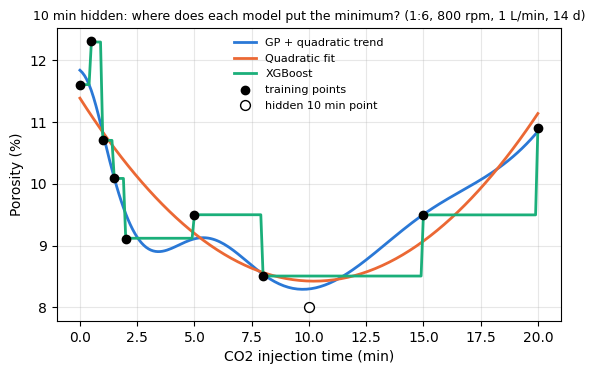

In [7]:
rid = "1:6_800rpm_1Lmin_14d"; g_obs = df[df.recipe == rid]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, col in [("GP + quadratic trend", "#2a78d6"), ("Quadratic fit", "#eb6834"), ("XGBoost", "#1baf7a")]:
    c = curves[name][curves[name].recipe == rid]; ax.plot(c.co2_time_min, c.pred, lw=2, color=col, label=name)
h = g_obs.co2_time_min == 10
ax.scatter(g_obs[~h].co2_time_min, g_obs[~h][TARGET], color="black", zorder=3, label="training points")
ax.scatter(g_obs[h].co2_time_min, g_obs[h][TARGET], facecolor="white", edgecolor="black", s=50, zorder=3, label="hidden 10 min point")
ax.set_xlabel("CO2 injection time (min)"); ax.set_ylabel("Porosity (%)"); ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=8)
ax.set_title("10 min hidden: where does each model put the minimum? (1:6, 800 rpm, 1 L/min, 14 d)", fontsize=9)
plt.show()

## 7. Final model: optimum with an uncertainty range
We train the GP + quadratic trend on all the data, then draw 2,000 possible curves from it. For each curve we record where porosity is lowest. The spread of those times is the **95% range for the optimum**, the result our paper needs.

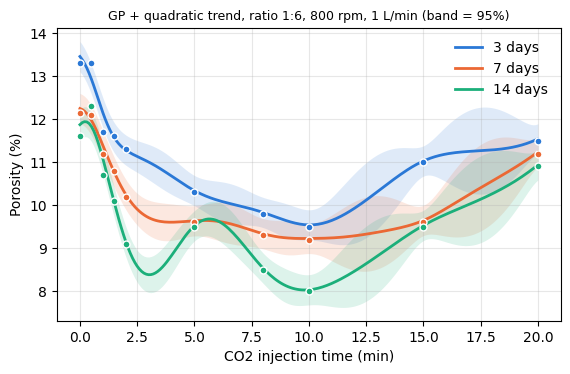

,"optimum (median, min)",95% range (min),lowest porosity (%)
curing days,,,
3,10.1,8.6 to 12.2,9.54
7,10.6,7.6 to 13.6,9.23
14,9.9,8.8 to 12.0,8.03


In [8]:
final = GP(trend=True).fit(df)
rng = np.random.default_rng(42); rows = []
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for days, col in [(3, "#2a78d6"), (7, "#eb6834"), (14, "#1baf7a")]:
    Xg = pd.DataFrame({"co2_time_min": GRID, "cement_fraction": 1/7, "stirring_rpm": 800, "co2_flow_L_min": 1, "curing_days": days})
    mean_s, cov_s = final.gp.predict(X_of(Xg), return_cov=True)
    s, trend = final.sc.scale_[0], final.lr.predict(trend_of(Xg))
    draws = rng.multivariate_normal(mean_s, cov_s + 1e-9 * np.eye(len(GRID)), size=2000) * s + final.sc.mean_[0] + trend
    t_opt = GRID[draws.argmin(axis=1)]
    mu = mean_s * s + final.sc.mean_[0] + trend; sd = np.sqrt(np.clip(np.diag(cov_s), 0, None)) * s
    ax.fill_between(GRID, mu - 1.96 * sd, mu + 1.96 * sd, color=col, alpha=0.15, lw=0)
    ax.plot(GRID, mu, color=col, lw=2, label=f"{days} days")
    obs = df[(df.cement_ratio == "1:6") & (df.stirring_rpm == 800) & (df.co2_flow_L_min == 1) & (df.curing_days == days)]
    ax.scatter(obs.co2_time_min, obs[TARGET], color=col, edgecolor="white", zorder=3, s=25)
    rows.append({"curing days": days, "optimum (median, min)": np.median(t_opt),
                 "95% range (min)": f"{np.percentile(t_opt, 2.5):.1f} to {np.percentile(t_opt, 97.5):.1f}",
                 "lowest porosity (%)": round(mu.min(), 2)})
ax.set_xlabel("CO2 injection time (min)"); ax.set_ylabel("Porosity (%)"); ax.grid(alpha=0.3); ax.legend(frameon=False)
ax.set_title("GP + quadratic trend, ratio 1:6, 800 rpm, 1 L/min (band = 95%)", fontsize=9); plt.show()
pd.DataFrame(rows).set_index("curing days")

## 8. Summary table

In [9]:
summary = pd.DataFrame({
    "R2 random split (misleading)": random_split["R2"],
    "R2 leave-one-time-out": loto["R2"],
    "RMSE leave-one-time-out": loto["RMSE"],
    "optimum found, 10 min hidden": peak["hide 10: optimum found (median, min)"],
    "within 2 min, 8+10 min hidden": peak["hide 8+10: within 2 min"],
})
summary

,R2 random split (misleading),R2 leave-one-time-out,RMSE leave-one-time-out,"optimum found, 10 min hidden","within 2 min, 8+10 min hidden"
model,,,,,
GP,0.985,0.684,0.744,9.5,0%
GP + quadratic trend,0.957,0.450,0.982,9.8,0%
Linear regression,0.269,-0.483,1.612,20.0,0%
MLP,0.928,0.789,0.608,8.1,17%
Quadratic fit,NaN,0.405,1.021,10.5,100%
Random forest,0.998,0.595,0.842,6.6,11%
SVR,0.840,0.748,0.664,8.2,84%
XGBoost,1.000,0.592,0.845,8.0,0%


## 9. How to read the results (from the run on 23 Oct 2026)
* **Random split scores are near perfect** (R2 0.93 to 1.00 for most models). That only shows the rows are near-copies; it is not a result for the paper.
* **Leave-one-time-out is the honest score.** Best: MLP 0.79, SVR 0.75, GP 0.68. The biggest errors are at the edges (0 and 20 min, data on one side only) and in the first 2 min, where porosity jumps up at 0.5 min and then drops fast.
* **Finding the optimum with the 10 min data hidden:** quadratic fit, XGBoost, GP and GP + quadratic trend all put the minimum within 2 min of 10 min for every recipe.
* **With both 8 and 10 min hidden**, only the quadratic fit (100%) and SVR (84%) still find it. Too little data is left near the valley, so the lab should test more times between 5 and 15 min.
* **Final GP + quadratic trend:** optimum about 10 min, with a 95% range of about 8.6 to 12.2 min (3 days), 7.6 to 13.6 min (7 days) and 8.8 to 12.0 min (14 days). This optimum *with a range* is the result the paper needs.
* **Caution:** the GP's 95% bands covered only 63 to 77% of hidden points (target 95%), so they are too narrow at untested times. Cement ratio, stirring and flow effects in this file are fixed percentages. Treat all numbers as a test of the method until the raw lab data arrives.